<a href="https://colab.research.google.com/github/AdityaPatil1705/Data-Mining/blob/main/HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install numpy pandas matplotlib scipy

In [2]:
from itertools import combinations
from collections import Counter
from pathlib import Path
import heapq

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from IPython.display import display

transactions = [
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter", "Eggs"],
    ["Milk", "Cereal"],
    ["Bread", "Eggs"],
    ["Milk", "Cereal", "Yogurt"],
    ["Diapers", "Beer"],
    ["Diapers", "Beer", "Chips"],
    ["Apples", "Bananas"],
    ["Apples", "Bananas", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Cereal", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Apples", "Milk"],
    ["Diapers", "Beer", "Bread", "Eggs"],
    ["Yogurt", "Cereal"],
    ["Bread", "Butter", "Bananas", "Milk"],
    ["Milk", "Eggs"],
    ["Apples", "Bananas", "Yogurt"],
    ["Bread", "Butter", "Cereal", "Milk"],
    ["Chips", "Salsa"],
]

transactions = [frozenset(t) for t in transactions]

MIN_SUP = 0.25
MIN_CONF = 0.60

def itemset_text(items):
    return "{" + ", ".join(sorted(items)) + "}"

print("Transactions:", len(transactions))

Transactions: 20


In [3]:
def support(candidate_itemset, transactions):
    """Fraction of transactions containing every candidate item."""
    if not transactions:
        raise ValueError("Transactions cannot be empty.")

    candidate = frozenset(candidate_itemset)

    return sum(
        candidate.issubset(transaction)
        for transaction in transactions
    ) / len(transactions)


def confidence(antecedent, consequent, transactions):
    """P(consequent | antecedent)."""
    antecedent = frozenset(antecedent)
    consequent = frozenset(consequent)

    if not antecedent or not consequent:
        raise ValueError("Both rule sides must be nonempty.")

    if antecedent & consequent:
        raise ValueError("Rule sides must be disjoint.")

    antecedent_support = support(antecedent, transactions)

    if antecedent_support == 0:
        raise ValueError("Confidence is undefined for zero-support antecedents.")

    return (
        support(antecedent | consequent, transactions)
        / antecedent_support
    )


def lift(antecedent, consequent, transactions):
    consequent_support = support(consequent, transactions)

    if consequent_support == 0:
        raise ValueError("Lift is undefined for zero-support consequents.")

    return (
        confidence(antecedent, consequent, transactions)
        / consequent_support
    )


print("Support of Bread:", support({"Bread"}, transactions))
print(
    "Confidence of Butter -> Bread:",
    confidence({"Butter"}, {"Bread"}, transactions),
)

Support of Bread: 0.4
Confidence of Butter -> Bread: 1.0


In [4]:
def join_and_prune(previous_level, target_size):
    """
    Join sorted itemsets sharing their first target_size - 2 items.
    Prune candidates with any missing immediate subset.
    """
    previous_level = set(previous_level)
    ordered = sorted(tuple(sorted(s)) for s in previous_level)

    joined = set()

    for i, left in enumerate(ordered):
        for right in ordered[i + 1:]:
            if left[:-1] != right[:-1]:
                continue

            candidate = frozenset(left) | frozenset(right)

            if len(candidate) == target_size:
                joined.add(candidate)

    kept = set()
    pruned = set()

    for candidate in joined:
        all_subsets_frequent = all(
            frozenset(subset) in previous_level
            for subset in combinations(
                sorted(candidate), target_size - 1
            )
        )

        if all_subsets_frequent:
            kept.add(candidate)
        else:
            pruned.add(candidate)

    return kept, pruned, joined

In [5]:
def apriori(transactions, min_sup):
    if not 0 < min_sup <= 1:
        raise ValueError("min_sup must be in (0, 1].")

    transactions = [frozenset(t) for t in transactions]

    if not transactions:
        raise ValueError("Transactions cannot be empty.")

    items = sorted(set().union(*transactions))
    singletons = {frozenset([item]) for item in items}

    frequent_supports = {}

    current_level = {
        candidate
        for candidate in singletons
        if support(candidate, transactions) >= min_sup
    }

    for candidate in current_level:
        frequent_supports[candidate] = support(
            candidate, transactions
        )

    trace = [{
        "k": 1,
        "joined_candidates": len(singletons),
        "subset_pruned": 0,
        "counted_candidates": len(singletons),
        "frequent_itemsets": len(current_level),
        "pruned_itemsets": [],
    }]

    k = 2

    while current_level:
        candidates, pruned, joined = join_and_prune(
            current_level, k
        )

        next_level = set()

        for candidate in candidates:
            candidate_support = support(candidate, transactions)

            if candidate_support >= min_sup:
                next_level.add(candidate)
                frequent_supports[candidate] = candidate_support

        trace.append({
            "k": k,
            "joined_candidates": len(joined),
            "subset_pruned": len(pruned),
            "counted_candidates": len(candidates),
            "frequent_itemsets": len(next_level),
            "pruned_itemsets": [
                itemset_text(s)
                for s in sorted(
                    pruned, key=lambda s: tuple(sorted(s))
                )
            ],
        })

        current_level = next_level
        k += 1

    return frequent_supports, trace


frequent_supports, apriori_trace = apriori(
    transactions, MIN_SUP
)

frequent_table = pd.DataFrame([
    {
        "k": len(items),
        "Itemset": itemset_text(items),
        "Count": round(sup * len(transactions)),
        "Support": sup,
    }
    for items, sup in frequent_supports.items()
]).sort_values(["k", "Itemset"]).reset_index(drop=True)

print("Frequent itemsets:")
display(frequent_table)

print("Candidate generation and pruning:")
display(pd.DataFrame(apriori_trace))

Frequent itemsets:


,k,Itemset,Count,Support
0,1,{Bread},8,0.40
1,1,{Butter},6,0.30
2,1,{Cereal},5,0.25
3,1,{Eggs},6,0.30
4,1,{Milk},11,0.55
5,2,"{Bread, Butter}",6,0.30
6,2,"{Bread, Eggs}",5,0.25
7,2,"{Bread, Milk}",5,0.25
8,2,"{Butter, Milk}",5,0.25
9,3,"{Bread, Butter, Milk}",5,0.25


Candidate generation and pruning:


,k,joined_candidates,subset_pruned,counted_candidates,frequent_itemsets,pruned_itemsets
0,1,12,0,12,5,[]
1,2,10,0,10,4,[]
2,3,3,2,1,1,"[{Bread, Butter, Eggs}, {Bread, Eggs, Milk}]"
3,4,0,0,0,0,[]


In [6]:
target = frozenset({"Butter", "Bread", "Eggs"})

subset_rows = []

for size in [1, 2, 3]:
    for subset in combinations(sorted(target), size):
        subset_rows.append({
            "Size": size,
            "Itemset": itemset_text(subset),
            "Support": support(subset, transactions),
            "Frequent": support(subset, transactions) >= MIN_SUP,
        })

display(pd.DataFrame(subset_rows))

frequent_pairs = {
    items for items in frequent_supports
    if len(items) == 2
}

kept_triples, pruned_triples, joined_triples = join_and_prune(
    frequent_pairs, 3
)

print("Generated by join:", target in joined_triples)
print("Pruned by subset test:", target in pruned_triples)
print("Counted after pruning:", target in kept_triples)

,Size,Itemset,Support,Frequent
0,1,{Bread},0.40,True
1,1,{Butter},0.30,True
2,1,{Eggs},0.30,True
3,2,"{Bread, Butter}",0.30,True
4,2,"{Bread, Eggs}",0.25,True
5,2,"{Butter, Eggs}",0.15,False
6,3,"{Bread, Butter, Eggs}",0.15,False


Generated by join: True
Pruned by subset test: True
Counted after pruning: False


In [7]:
def apriori_rules(frequent_supports, transactions, min_conf):
    if not 0 <= min_conf <= 1:
        raise ValueError("min_conf must be in [0, 1].")

    rules = []
    trace = []

    ordered_itemsets = sorted(
        frequent_supports,
        key=lambda s: (len(s), tuple(sorted(s))),
    )

    for full_itemset in ordered_itemsets:
        if len(full_itemset) < 2:
            continue

        candidates = {
            frozenset([item]) for item in full_itemset
        }

        consequent_size = 1
        joined_count = len(candidates)
        subset_pruned_count = 0

        while candidates:
            passing = set()

            for consequent in sorted(
                candidates, key=lambda s: tuple(sorted(s))
            ):
                antecedent = full_itemset - consequent

                rule_confidence = confidence(
                    antecedent, consequent, transactions
                )

                if rule_confidence >= min_conf:
                    passing.add(consequent)

                    rules.append({
                        "Antecedent": itemset_text(antecedent),
                        "Consequent": itemset_text(consequent),
                        "Support": frequent_supports[full_itemset],
                        "Confidence": rule_confidence,
                        "Lift": lift(
                            antecedent, consequent, transactions
                        ),
                    })

            trace.append({
                "Frequent itemset": itemset_text(full_itemset),
                "Consequent size": consequent_size,
                "Joined candidates": joined_count,
                "Subset-pruned": subset_pruned_count,
                "Confidence-tested": len(candidates),
                "Confidence-failed": len(candidates) - len(passing),
                "Passed": len(passing),
            })

            # A rule must retain a nonempty antecedent.
            if consequent_size >= len(full_itemset) - 1:
                break

            # Only passing consequents are extended.
            candidates, pruned, joined = join_and_prune(
                passing, consequent_size + 1
            )

            joined_count = len(joined)
            subset_pruned_count = len(pruned)
            consequent_size += 1

    columns = [
        "Antecedent", "Consequent",
        "Support", "Confidence", "Lift",
    ]

    rules_table = pd.DataFrame(rules, columns=columns)

    if not rules_table.empty:
        rules_table = rules_table.sort_values(
            ["Lift", "Confidence", "Support"],
            ascending=False,
        ).reset_index(drop=True)

    return rules_table, pd.DataFrame(trace)


rules_table, rules_trace = apriori_rules(
    frequent_supports, transactions, MIN_CONF
)

print("All qualifying association rules:")
display(rules_table.round(4))

print("Rule-generation trace:")
display(rules_trace)

All qualifying association rules:


,Antecedent,Consequent,Support,Confidence,Lift
0,"{Bread, Milk}",{Butter},0.25,1.0000,3.3333
1,{Butter},"{Bread, Milk}",0.25,0.8333,3.3333
2,{Butter},{Bread},0.30,1.0000,2.5000
3,"{Butter, Milk}",{Bread},0.25,1.0000,2.5000
4,{Bread},"{Butter, Milk}",0.25,0.6250,2.5000
5,{Bread},{Butter},0.30,0.7500,2.5000
6,{Eggs},{Bread},0.25,0.8333,2.0833
7,{Bread},{Eggs},0.25,0.6250,2.0833
8,{Butter},{Milk},0.25,0.8333,1.5152
9,"{Bread, Butter}",{Milk},0.25,0.8333,1.5152


Rule-generation trace:


,Frequent itemset,Consequent size,Joined candidates,Subset-pruned,Confidence-tested,Confidence-failed,Passed
0,"{Bread, Butter}",1,2,0,2,0,2
1,"{Bread, Eggs}",1,2,0,2,0,2
2,"{Bread, Milk}",1,2,0,2,1,1
3,"{Butter, Milk}",1,2,0,2,1,1
4,"{Bread, Butter, Milk}",1,3,0,3,0,3
5,"{Bread, Butter, Milk}",2,3,0,3,1,2


Dataset shape: (370, 2)


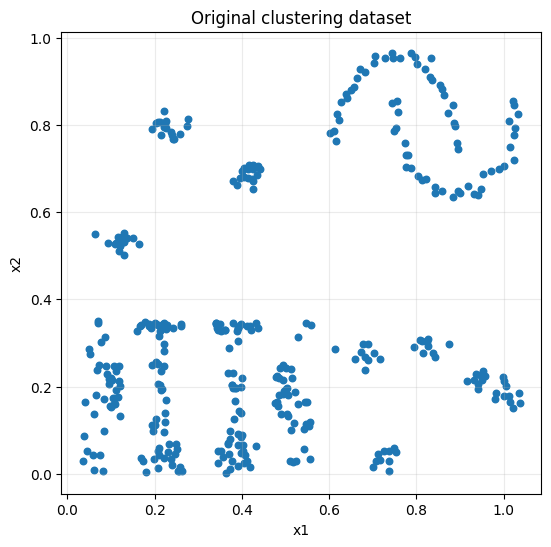

In [8]:
data_path = Path("clustering.txt")

if not data_path.exists():
    raise FileNotFoundError(
        "Put clustering.txt in the same folder as this notebook."
    )

X = np.loadtxt(data_path, delimiter=",")

if X.ndim != 2 or X.shape[1] != 2:
    raise ValueError("Expected two numerical columns.")

if not np.isfinite(X).all():
    raise ValueError("Dataset contains non-finite values.")

print("Dataset shape:", X.shape)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=22)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Original clustering dataset")
plt.gca().set_aspect("equal", adjustable="box")
plt.grid(alpha=0.25)
plt.show()

In [9]:
def min_dist(distance_a, distance_b):
    """Single-linkage distance update."""
    return min(distance_a, distance_b)


def max_dist(distance_a, distance_b):
    """Complete-linkage distance update."""
    return max(distance_a, distance_b)


def hac(X, cluster_distance):
    """
    Hierarchical agglomerative clustering.

    cluster_distance is min_dist or max_dist and combines cached
    distances after a merge.

    Returns a SciPy-compatible linkage matrix:
    [left_cluster, right_cluster, merge_distance, merged_size].
    """
    X = np.asarray(X, dtype=float)

    if X.ndim != 2 or len(X) < 2:
        raise ValueError("Expected at least two data points.")

    if not np.isfinite(X).all():
        raise ValueError("All coordinates must be finite.")

    if cluster_distance not in (min_dist, max_dist):
        raise ValueError("Use min_dist or max_dist.")

    n = len(X)
    active = set(range(n))
    sizes = {i: 1 for i in range(n)}

    distances = {}
    heap = []
    merges = []

    def pair_key(a, b):
        return (min(a, b), max(a, b))

    # Point-to-point distances are computed only at initialization.
    for i in range(n):
        for j in range(i + 1, n):
            distance = float(np.linalg.norm(X[i] - X[j]))
            distances[(i, j)] = distance
            heapq.heappush(heap, (distance, i, j))

    for step in range(n - 1):
        # Ignore stale entries involving previously merged clusters.
        while True:
            distance, a, b = heapq.heappop(heap)

            if a in active and b in active:
                break

        new_id = n + step
        others = sorted(active - {a, b})
        new_size = sizes[a] + sizes[b]

        merges.append([a, b, distance, new_size])

        # Update only distances involving the newly merged cluster.
        for c in others:
            updated_distance = cluster_distance(
                distances[pair_key(a, c)],
                distances[pair_key(b, c)],
            )

            key = pair_key(new_id, c)
            distances[key] = updated_distance

            heapq.heappush(
                heap,
                (updated_distance, key[0], key[1]),
            )

        # Remove obsolete distances after using them.
        for c in others:
            del distances[pair_key(a, c)]
            del distances[pair_key(b, c)]

        del distances[pair_key(a, b)]

        active.remove(a)
        active.remove(b)
        active.add(new_id)
        sizes[new_id] = new_size

    return np.asarray(merges, dtype=float)

In [10]:
def cluster_membership(linkage_matrix, n_points, n_clusters):
    """
    Apply the first n_points - n_clusters merges.
    This gives exactly n_clusters, even when merge heights tie.
    """
    if not 1 <= n_clusters <= n_points:
        raise ValueError("Invalid target number of clusters.")

    members = {
        i: [i] for i in range(n_points)
    }

    for step, row in enumerate(
        linkage_matrix[:n_points - n_clusters]
    ):
        a, b = int(row[0]), int(row[1])
        new_id = n_points + step

        members[new_id] = members.pop(a) + members.pop(b)

    labels = np.empty(n_points, dtype=int)

    ordered_clusters = sorted(
        members.values(), key=lambda indices: min(indices)
    )

    for label, indices in enumerate(ordered_clusters):
        labels[indices] = label

    return labels

Single-linkage cluster sizes:
[10, 10, 10, 16, 17, 17, 20, 35, 35, 40, 40, 60, 60]

Complete-linkage cluster sizes:
[10, 13, 13, 16, 19, 30, 32, 34, 34, 34, 38, 42, 55]


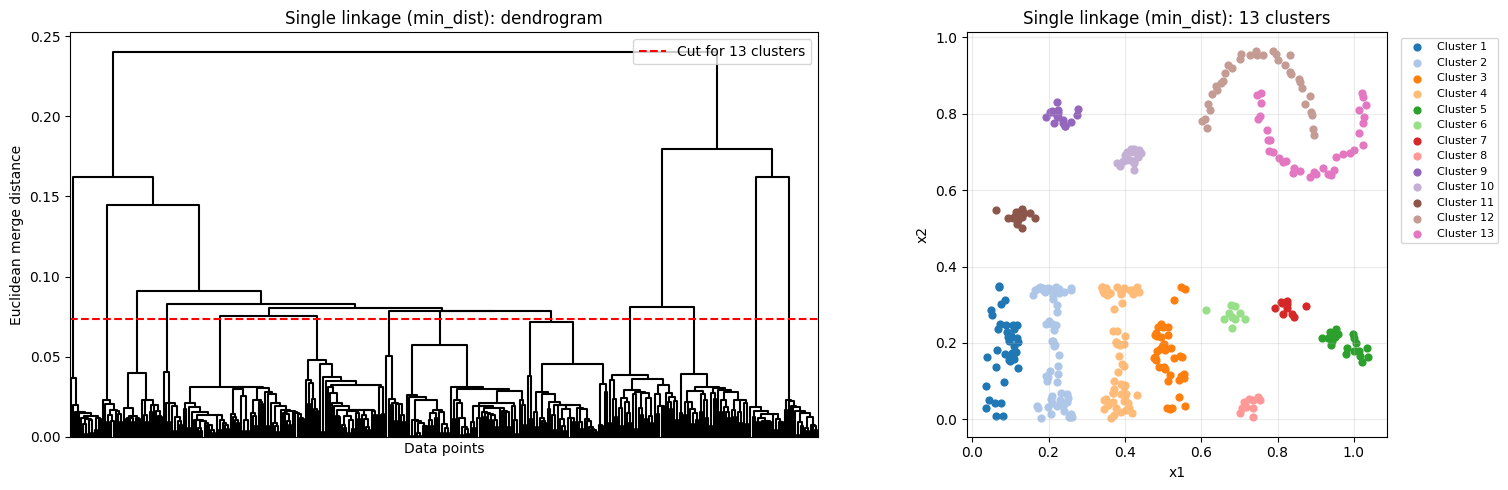

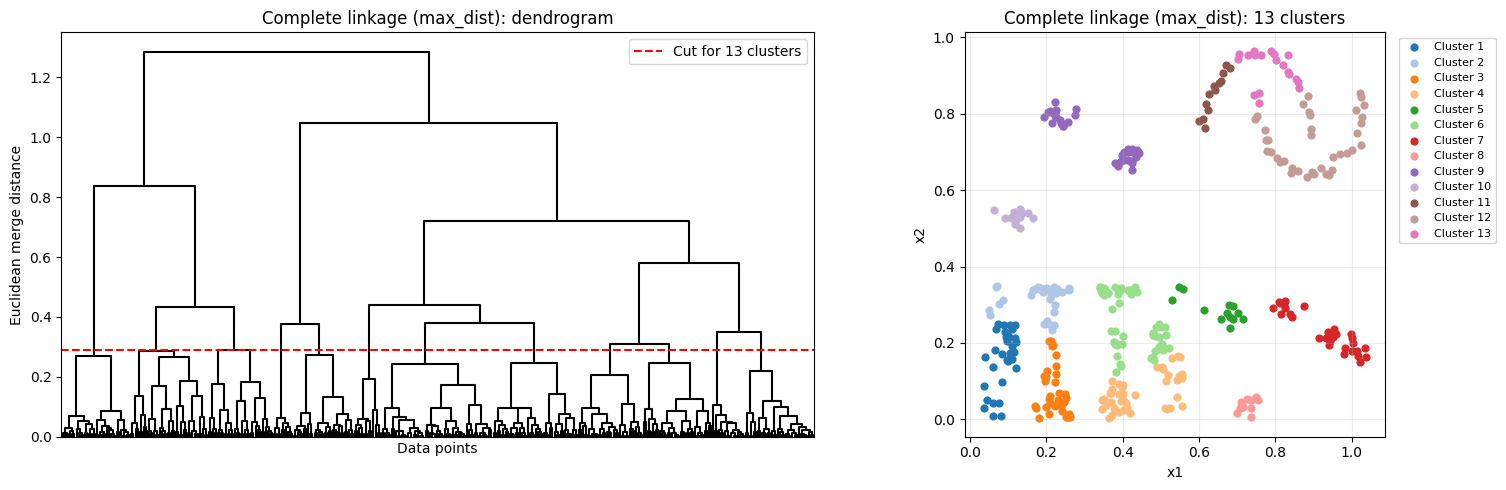

In [11]:
Z_single = hac(X, min_dist)
Z_complete = hac(X, max_dist)

labels_single = cluster_membership(Z_single, len(X), 13)
labels_complete = cluster_membership(Z_complete, len(X), 13)

print("Single-linkage cluster sizes:")
print(sorted(Counter(labels_single).values()))

print("\nComplete-linkage cluster sizes:")
print(sorted(Counter(labels_complete).values()))


def plot_hac_result(X, linkage_matrix, labels, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    dendrogram(
        linkage_matrix,
        ax=axes[0],
        no_labels=True,
        color_threshold=0,
        above_threshold_color="black",
    )

    # Mark the cut when a horizontal cut can distinguish 13 clusters.
    n = len(X)
    k = len(np.unique(labels))
    applied_merges = n - k

    if 0 < applied_merges < len(linkage_matrix):
        last_included = linkage_matrix[applied_merges - 1, 2]
        first_excluded = linkage_matrix[applied_merges, 2]

        if last_included < first_excluded:
            cut_height = (last_included + first_excluded) / 2
            axes[0].axhline(
                cut_height,
                color="red",
                linestyle="--",
                label=f"Cut for {k} clusters",
            )
            axes[0].legend()

    axes[0].set_title(f"{title}: dendrogram")
    axes[0].set_xlabel("Data points")
    axes[0].set_ylabel("Euclidean merge distance")

    cmap = plt.get_cmap("tab20")

    for cluster_id in np.unique(labels):
        points = X[labels == cluster_id]

        axes[1].scatter(
            points[:, 0],
            points[:, 1],
            color=cmap(int(cluster_id)),
            s=24,
            label=f"Cluster {cluster_id + 1}",
        )

    axes[1].set_title(f"{title}: {k} clusters")
    axes[1].set_xlabel("x1")
    axes[1].set_ylabel("x2")
    axes[1].set_aspect("equal", adjustable="box")
    axes[1].grid(alpha=0.25)
    axes[1].legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8,
    )

    plt.tight_layout()
    plt.show()


plot_hac_result(
    X, Z_single, labels_single, "Single linkage (min_dist)"
)

plot_hac_result(
    X, Z_complete, labels_complete, "Complete linkage (max_dist)"
)

In [12]:
# Every frequent itemset meets the support threshold.
assert all(
    sup >= MIN_SUP for sup in frequent_supports.values()
)

# Every reported rule meets the confidence threshold.
assert (rules_table["Confidence"] >= MIN_CONF).all()

# HAC performs exactly n - 1 merges.
assert Z_single.shape == (len(X) - 1, 4)
assert Z_complete.shape == (len(X) - 1, 4)

# Both cuts produce exactly 13 nonempty clusters.
assert len(np.unique(labels_single)) == 13
assert len(np.unique(labels_complete)) == 13

# The final merge includes every point.
assert int(Z_single[-1, 3]) == len(X)
assert int(Z_complete[-1, 3]) == len(X)

print("All basic checks passed.")

All basic checks passed.
